# MFPCA amb correlació entre components "creuades" (permutació aleatòria)

Autor: Leonel Fernando Nabaza Ruibal

Nova variant: en lloc de correlacionar la component $m$ de $X^{(1)}$ amb la
**mateixa** component $m$ de $X^{(2)}$, la correlacionem amb una component
**diferent i escollida a l'atzar** $\sigma(m)$. És a dir, construïm directament
la correlació a nivell dels "scores veritables" del model generador, amb una
permutació $\sigma$ fixa:

$$
\mathrm{corr}\big(\xi^{(1)}_{\sigma(m)},\ \xi^{(2)}_{m}\big) = \rho, \qquad
\mathrm{corr}\big(\xi^{(1)}_{m'},\ \xi^{(2)}_{m}\big) = 0 \ \text{ si } m'\neq\sigma(m)
$$

Com que ara l'índex que es correlaciona no coincideix en general, **no té sentit
comparar només índex $k$ amb índex $k$** com als notebooks anteriors: cal mirar
la matriu completa de correlacions entre totes les components de X1 i totes les
de X2.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from FDApy.representation.functional_data import DenseFunctionalData, MultivariateFunctionalData
from FDApy.representation.argvals import DenseArgvals
from FDApy.representation.values import DenseValues
from FDApy.preprocessing.dim_reduction.mfpca import MFPCA
from FDApy.preprocessing.dim_reduction.ufpca import UFPCA

rng = np.random.default_rng(7)


---
# Part 1 — Funcions i generació de les dades

Fem servir $M=5$ components "veritables" amb variàncies ben separades
$\lambda_1 > \dots > \lambda_5$, de manera que la FPCA les pugui recuperar en el
mateix ordre que les hem generat (si les variàncies estiguessin molt juntes,
l'ordre estimat podria no coincidir amb l'ordre real).

$$
X^{(1)}(t) = \sum_{m=1}^{5} \xi^{(1)}_m\, \Phi_m(t) + \varepsilon^{(1)}(t), \qquad
X^{(2)}(t) = \sum_{m=1}^{5} \xi^{(2)}_m\, \Psi_m(t) + \varepsilon^{(2)}(t)
$$

on $\Phi_m$ és una base de Fourier i $\Psi_m$ la mateixa base desplaçada (una
"forma" diferent per a X2, com als notebooks anteriors).

**Els scores** $\xi^{(1)}_m \sim N(0,\lambda_m)$ són independents entre ells.
Triem una permutació aleatòria $\sigma$ de $\{1,\dots,5\}$ i definim:

$$
\xi^{(2)}_m \;=\; \rho\sqrt{\tfrac{\lambda_m}{\lambda_{\sigma(m)}}}\;\xi^{(1)}_{\sigma(m)} \;+\; \sqrt{1-\rho^2}\;\eta_m,
\qquad \eta_m \sim N(0,\lambda_m) \text{ independent}
$$

Aquesta fórmula (anàloga a la del Notebook de correlació puntual, però ara
"aparellant" l'índex $m$ amb $\sigma(m)$ en lloc de $m$ amb $m$) garanteix
exactament $\mathrm{corr}(\xi^{(1)}_{\sigma(m)}, \xi^{(2)}_m) = \rho$ i
$\mathrm{Var}(\xi^{(2)}_m) = \lambda_m$, independentment dels valors concrets
de $\lambda$.


In [2]:
n = 300
t = np.linspace(0, 2*np.pi, 100)
argvals = DenseArgvals({'input_dim_0': t})

M = 5
lambdas = np.array([5.0, 4.0, 3.0, 2.0, 1.0])   # variancies ben separades


def fourier_basis(t, m):
    if m == 0:
        return np.ones_like(t)
    k = (m + 1) // 2
    return np.sqrt(2) * (np.sin(k*t) if m % 2 else np.cos(k*t))


Phi = np.stack([fourier_basis(t, m) for m in range(M)], axis=0)
Psi = np.roll(Phi, shift=11, axis=1)   # mateixa base, desplaçada (forma diferent)

rho = 0.9
sigma = rng.permutation(M)
print("Permutació sigma (component m de X2 <-> component sigma[m] de X1):", sigma)

xi1 = rng.normal(size=(n, M)) * np.sqrt(lambdas)
xi2 = np.zeros((n, M))
for m in range(M):
    sm = sigma[m]
    xi2[:, m] = (
        rho * np.sqrt(lambdas[m] / lambdas[sm]) * xi1[:, sm]
        + np.sqrt(1 - rho**2) * rng.normal(size=n) * np.sqrt(lambdas[m])
    )

X1 = xi1 @ Phi + 0.05 * rng.normal(size=(n, len(t)))
X2 = xi2 @ Psi + 0.05 * rng.normal(size=(n, len(t)))


Permutació sigma (component m de X2 <-> component sigma[m] de X1): [2 0 4 1 3]


## Construcció dels objectes funcionals

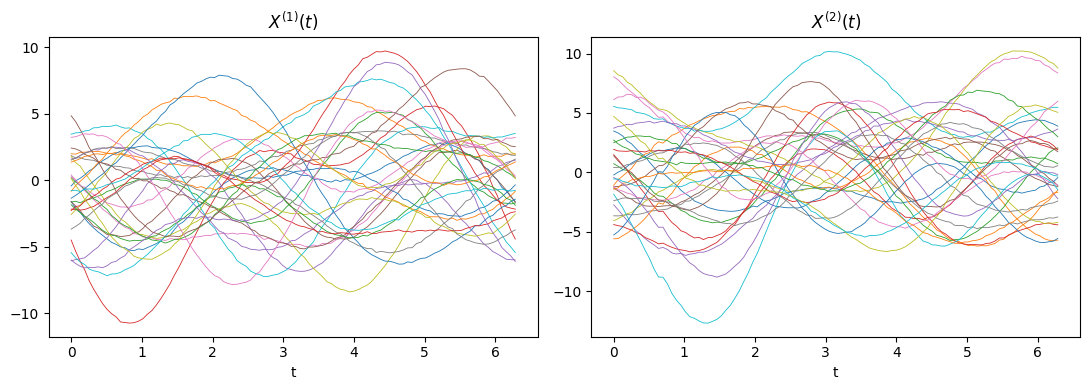

In [3]:
fd1 = DenseFunctionalData(argvals, DenseValues(X1))
fd2 = DenseFunctionalData(argvals, DenseValues(X2))
mData = MultivariateFunctionalData([fd1, fd2])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t, X1[:30].T, linewidth=0.6)
axes[0].set_title("$X^{(1)}(t)$")
axes[0].set_xlabel("t")
axes[1].plot(t, X2[:30].T, linewidth=0.6)
axes[1].set_title("$X^{(2)}(t)$")
axes[1].set_xlabel("t")
plt.tight_layout()
plt.show()


---
# Part 2 — Ajust de la MFPCA i de la FPCA univariant per separat


In [4]:
K = M  # estudiem les mateixes 5 components que el model generador

uniExpansions = [
    {'method': 'UFPCA', 'n_components': 10},
    {'method': 'UFPCA', 'n_components': 10},
]
mfpca = MFPCA(n_components=K, method='covariance', univariate_expansions=uniExpansions)
mfpca.fit(mData)

print("Valors propis MFPCA:", np.round(mfpca.eigenvalues, 3))


Valors propis MFPCA: [50.544 46.665 35.068 23.069 17.201]


In [5]:
ufpca1 = UFPCA(n_components=K, method='covariance')
ufpca1.fit(fd1)
scores1 = ufpca1.transform(fd1)

ufpca2 = UFPCA(n_components=K, method='covariance')
ufpca2.fit(fd2)
scores2 = ufpca2.transform(fd2)

print("Valors propis X1:", np.round(ufpca1.eigenvalues, 3))
print("Valors propis X2:", np.round(ufpca2.eigenvalues, 3))


Valors propis X1: [29.976 23.725 18.187 11.561  6.247]
Valors propis X2: [31.539 23.065 18.137 12.387  6.204]


---
# Part 3 — Matriu completa de correlacions entre components

Ara, en lloc de comparar només $k$ amb $k$, calculem **tota la matriu**
$K\times K$ de correlacions $\mathrm{corr}(\text{scores1}[:,k],\ \text{scores2}[:,l])$
per a totes les parelles $(k,l)$, i la comparem amb la permutació $\sigma$ que hem
imposat.


Matriu corr(scores1[k], scores2[l]):
 [[ 0.096  0.866 -0.21  -0.018 -0.002]
 [ 0.079  0.04   0.237 -0.868  0.042]
 [ 0.864 -0.07  -0.018  0.094  0.21 ]
 [-0.212  0.02   0.034  0.016  0.87 ]
 [ 0.029  0.232  0.831  0.236 -0.018]]


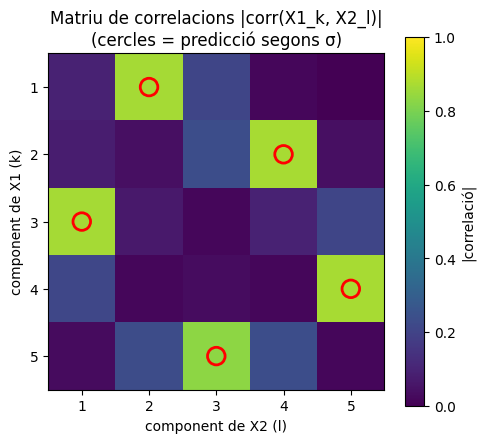

In [6]:
Mcorr = np.zeros((K, K))
for k in range(K):
    for l in range(K):
        Mcorr[k, l] = np.corrcoef(scores1[:, k], scores2[:, l])[0, 1]

np.set_printoptions(precision=3, suppress=True)
print("Matriu corr(scores1[k], scores2[l]):\n", Mcorr)

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(np.abs(Mcorr), cmap="viridis", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="|correlació|")
ax.set_xlabel("component de X2 (l)")
ax.set_ylabel("component de X1 (k)")
ax.set_xticks(range(K))
ax.set_yticks(range(K))
ax.set_xticklabels(range(1, K+1))
ax.set_yticklabels(range(1, K+1))

# marquem amb un cercle vermell on la permutacio predeia el pic (k=sigma[m], l=m)
for m in range(K):
    ax.scatter(m, sigma[m], s=160, facecolors='none', edgecolors='red', linewidths=2)

ax.set_title("Matriu de correlacions |corr(X1_k, X2_l)|\n(cercles = predicció segons σ)")
plt.tight_layout()
plt.show()


---
# Part 4 — Comparació amb la permutació imposada

Comprovem numèricament que els pics de correlació cauen exactament a les posicions
$(k,l) = (\sigma(m), m)$ previstes per la permutació.


In [7]:
print(f"Correlació original imposada (rho): {rho}\n")
print("Comparació pic esperat vs. observat:")
for m in range(M):
    k_esperat = sigma[m]
    valor = Mcorr[k_esperat, m]
    print(f"  X2 component {m+1}  <->  X1 component {k_esperat+1}  (σ): corr observada = {valor:+.4f}")

# verifiquem tambe que la resta de la fila/columna es pràcticament 0
mascara = np.ones((K, K), dtype=bool)
for m in range(M):
    mascara[sigma[m], m] = False
print(f"\nMitjana |correlació| fora dels pics esperats: {np.mean(np.abs(Mcorr[mascara])):.4f}")


Correlació original imposada (rho): 0.9

Comparació pic esperat vs. observat:
  X2 component 1  <->  X1 component 3  (σ): corr observada = +0.8643
  X2 component 2  <->  X1 component 1  (σ): corr observada = +0.8658
  X2 component 3  <->  X1 component 5  (σ): corr observada = +0.8309
  X2 component 4  <->  X1 component 2  (σ): corr observada = -0.8676
  X2 component 5  <->  X1 component 4  (σ): corr observada = +0.8698

Mitjana |correlació| fora dels pics esperats: 0.0956


---
# Conclusió

Quan la correlació no es dona entre les components del mateix índex, sinó entre
índexs diferents (segons una permutació $\sigma$ escollida a l'atzar), **la FPCA
univariant de cada variable la segueix capturant correctament** — però ara cal
mirar la **matriu completa** de correlacions entre totes les components de X1 i
totes les de X2, no només la diagonal. Els pics de correlació (≈0.9, molt per
sobre del soroll de la resta de la matriu) apareixen exactament a les posicions
que marca $\sigma$, confirmant que:

- l'ordre en què la FPCA numera les seves components és **independent** de quina
  variable concreta de l'altra element hi estigui correlacionada,
- per detectar aquest tipus de relació cal estudiar la matriu de covariàncies/
  correlacions **sencera** entre els scores, no només aparellar per índex —
  això és precisament el que fa, de manera interna, l'algorisme de MFPCA quan
  combina totes dues variables en una única descomposició conjunta.
